In [5]:
import math
from decimal import Decimal, getcontext
import numpy as np
import matplotlib.pyplot as plt

## Задача 2.1.

Дана зависимость скорости от коэффициента сопротивления:

$$v(c) = \frac{gm}{c}\Big(1-e^{-(c/m)t}\Big), \qquad m=68.1\text{ кг},\ t=10\text{ с},\ g=9.8\text{ м/с}^2.$$

Нужно найти такое $c$, при котором $v(c)=40$ м/с. Для этого найдём корень уравнения

$$f(c) = v(c) - 40 = 0.$$

1. Найти отрезок $[a_i,b_i]$, содержащий корень. Для этого проверим условие теоремы Больцано — Коши: $f(a_i)f(b_i)\le 0$.
2. Построить приближение $\tilde x_i$ с заданной точностью $|\tilde x_i-x^*|\le\varepsilon$.

In [6]:
def f_main(c, m=68.1, t=10.0, g=9.8):
    v = (g * m / c) * (1 - math.exp(-(c / m) * t))
    return v - 40.0

a0, b0 = 14.0, 16.0
print("f(a0) =", f_main(a0), " f(b0) =", f_main(b0))
print("f(a0)*f(b0) < 0 ?", f_main(a0) * f_main(b0) < 0)

f(a0) = 1.5686993148036095  f(b0) = -2.2687619693477643
f(a0)*f(b0) < 0 ? True


На концах отрезка $[14,16]$ функция имеет разные знаки, поэтому этот отрезок содержит корень.

In [7]:
calls_f = 0  # Глобальный счетчик вызовов функции
eps = 1e-4

def f_main(c, m=68.1, t=10.0, g=9.8):
    global calls_f
    calls_f += 1
    
    v = (g * m / c) * (1 - math.exp(-(c / m) * t))
    return v - 40.0

### Метод бисекции (половинного деления)

Алгоритм:

1. Вычислить середину отрезка $c_n=(a_n+b_n)/2$.
2. Если $f(c_n)=0$, корень найден.
3. Оставить ту половину отрезка, на концах которой функция меняет знак.
4. Повторять, пока отрезок не станет достаточно коротким.

Погрешность приближения ограничена половиной текущего отрезка:

$$|x_n-x^*|\le\frac{b_n-a_n}{2}=\frac{b_0-a_0}{2^{n+1}}.$$

Сходимость линейная с коэффициентом $q=1/2$: на каждой итерации длина отрезка уменьшается вдвое. Поэтому для точности $\varepsilon$ достаточно выбрать число итераций из условия

$$n\ge\log_2\!\left(\frac{b_0-a_0}{2\varepsilon}\right).$$

Надёжный критерий остановки — $\dfrac{b_n-a_n}{2}\le\varepsilon$. Ориентироваться только на малое значение $|f(c_n)|$ не всегда полезно: например, функция может касаться оси абсцисс, не пересекая её.

In [8]:
def bisection(a, b, eps):
    global calls_f
    calls_f = 0
    
    fa = f_main(a)
    fb = f_main(b)
    
    while (b - a) / 2.0 > eps:
        c = (a + b) / 2.0
        fc = f_main(c)
        
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    
    return (a + b) / 2.0

### Метод ложного положения (regula falsi)

Бисекция не учитывает значения $f(a_n)$ и $f(b_n)$ — она просто делит отрезок пополам. Метод ложного положения вместо этого проводит секущую через точки $(a_n,f(a_n))$ и $(b_n,f(b_n))$ и берёт точку её пересечения с осью абсцисс:

$$c_n = a_n - f(a_n)\,\frac{b_n-a_n}{f(b_n)-f(a_n)}.$$

Далее сохраняется та часть отрезка, на концах которой функция имеет разные знаки.

**Замечание.** Для сильно выпуклой или вогнутой функции один конец отрезка может долго оставаться неподвижным. Посмотрим, происходит ли это в нашем случае.

In [9]:
def false_position(a, b, eps):
    global calls_f
    calls_f = 0
    
    fa, fb = f_main(a), f_main(b)
    c = a
    stuck_left = stuck_right = 0
    max_stuck_left = max_stuck_right = 0

    while (b - a) > eps:
        c = a - fa * (b - a) / (fb - fa)
        fc = f_main(c)
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
            stuck_left += 1; stuck_right = 0   # левый конец (a) не сдвинулся
        else:
            a, fa = c, fc
            stuck_right += 1; stuck_left = 0   # правый конец (b) не сдвинулся
        max_stuck_left = max(max_stuck_left, stuck_left)
        max_stuck_right = max(max_stuck_right, stuck_right)

    fixed_end = "левый (a)" if max_stuck_left > max_stuck_right else "правый (b)"
    print(f"Дольше всего оставался неподвижным: {fixed_end} "
          f"(макс. серий подряд: слева={max_stuck_left}, справа={max_stuck_right})")
    return c

### Модифицированный метод ложного положения (Иллинойс)

Если один и тот же конец отрезка не сдвигается две итерации подряд, его значение функции делится пополам перед следующим построением секущей. Уменьшение $|f(a_n)|$ или $|f(b_n)|$ смещает точку пересечения секущей с осью абсцисс и помогает избежать застоя.

In [10]:
def illinois(a, b, eps):
    global calls_f
    calls_f = 0  # Обнуляем перед запуском
    
    fa, fb = f_main(a), f_main(b)
    ka = kb = 0
    c = a

    while (b - a) > eps:
        c = a - fa * (b - a) / (fb - fa)
        fc = f_main(c)
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
            ka += 1; kb = 0
            if ka >= 2:
                fa = fa / 2
        else:
            a, fa = c, fc
            kb += 1; ka = 0
            if kb >= 2:
                fb = fb / 2

    return c

По результатам видно, что метод Иллинойса находит тот же корень за меньшее число вычислений, чем бисекция. Он уменьшает влияние неподвижного конца и тем самым избегает стагнации.

### Сравнение трёх методов

In [11]:
root_b = bisection(a0, b0, eps)
calls_b = calls_f

root_fp = false_position(a0, b0, eps)
calls_fp = calls_f

root_il = illinois(a0, b0, eps)
calls_il = calls_f

print(f"{'Метод':<22} {'Корень c':<14} {'Вычислений f':<14} {'|f(c)|':<10}")
print(f"{'Бисекция':<22} {root_b:<14.6f} {calls_b:<14} {abs(f_main(root_b)):<10.2e}")
print(f"{'Ложное положение':<22} {root_fp:<14.6f} {calls_fp:<14} {abs(f_main(root_fp)):<10.2e}")
print(f"{'Иллинойс':<22} {root_il:<14.6f} {calls_il:<14} {abs(f_main(root_il)):<10.2e}")

Дольше всего оставался неподвижным: левый (a) (макс. серий подряд: слева=10, справа=1)
Метод                  Корень c       Вычислений f   |f(c)|    
Бисекция               14.780212      16             1.67e-05  
Ложное положение       14.780204      13             7.11e-15  
Иллинойс               14.780204      8              3.84e-12  


бисекция:        c=14.780212, вызовов=16
ложное положение: c=14.780204, вызовов=13
иллинойс:        c=14.780204, вызовов=8
x_ref = 14.780203831661


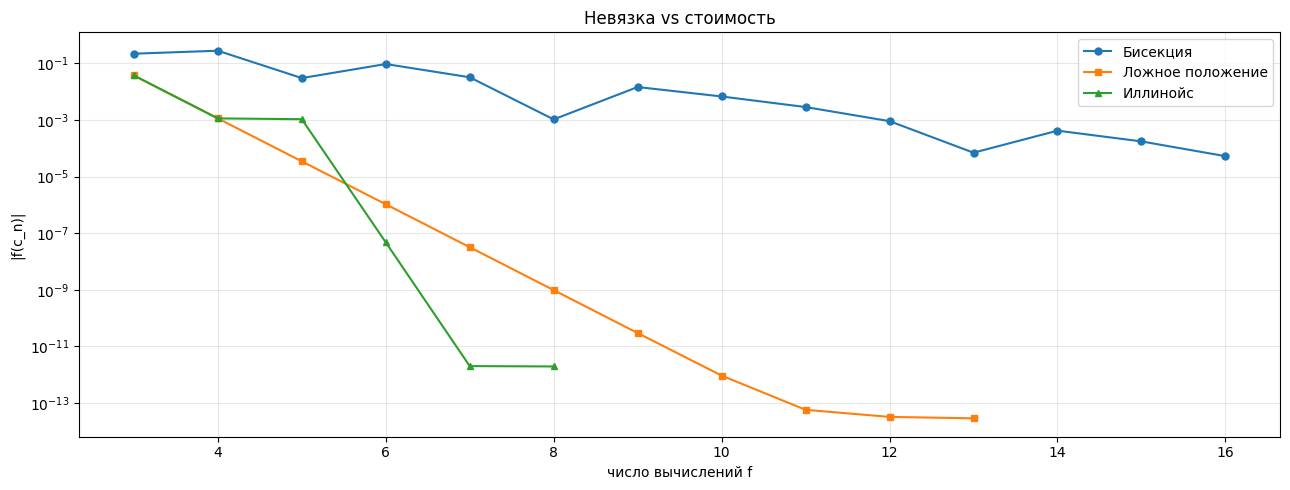

In [12]:
# Каждый элемент истории — кортеж (номер вызова f, точка c, невязка |f(c)|)

def bisection_hist(a, b, eps, max_iter=500):
    global calls_f          # нужен ТОЛЬКО из-за присваивания calls_f = 0
    calls_f = 0
    history = []
    fa, fb = f_main(a), f_main(b)      # вызовы 1 и 2
    for _ in range(max_iter):
        if (b - a) / 2.0 <= eps:
            break
        c = (a + b) / 2.0
        fc = f_main(c)
        history.append((calls_f, c, abs(fc)))
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return (a + b) / 2.0, history       # скобки обязательны!


def false_position_hist(a, b, eps, max_iter=500):
    global calls_f
    calls_f = 0
    history = []
    fa, fb = f_main(a), f_main(b)
    c = a
    for _ in range(max_iter):
        if (b - a) <= eps:
            break
        c = a - fa * (b - a) / (fb - fa)
        fc = f_main(c)
        history.append((calls_f, c, abs(fc)))
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return c, history


def illinois_hist(a, b, eps, max_iter=500):
    global calls_f
    calls_f = 0
    history = []
    fa, fb = f_main(a), f_main(b)
    ka = kb = 0
    c = a
    for _ in range(max_iter):
        if (b - a) <= eps:
            break
        c = a - fa * (b - a) / (fb - fa)
        fc = f_main(c)
        history.append((calls_f, c, abs(fc)))
        if fc == 0:
            break
        elif fa * fc < 0:
            b, fb = c, fc
            ka += 1; kb = 0
            if ka >= 2:
                fa = fa / 2
        else:
            a, fa = c, fc
            kb += 1; ka = 0
            if kb >= 2:
                fb = fb / 2
    return c, history

root_b,  hist_b  = bisection_hist(a0, b0, eps)
calls_b  = calls_f
root_fp, hist_fp = false_position_hist(a0, b0, eps)
calls_fp = calls_f
root_il, hist_il = illinois_hist(a0, b0, eps)
calls_il = calls_f

# опорный корень для оси Y: бисекция с очень строгим eps
x_ref, _ = bisection_hist(a0, b0, 1e-13)

print(f"бисекция:        c={root_b:.6f}, вызовов={calls_b}")
print(f"ложное положение: c={root_fp:.6f}, вызовов={calls_fp}")
print(f"иллинойс:        c={root_il:.6f}, вызовов={calls_il}")
print(f"x_ref = {x_ref:.12f}")

fig, axes = plt.subplots(1, figsize=(13, 5))
for hist, name, mk in [(hist_b,  'Бисекция',         'o'),
                       (hist_fp, 'Ложное положение', 's'),
                       (hist_il, 'Иллинойс',         '^')]:
    calls = [p[0] for p in hist]
    errs  = [max(abs(p[1] - x_ref), 1e-16) for p in hist]   # защита от нуля на лог-шкале
    ress  = [max(p[2], 1e-300) for p in hist]
    axes.semilogy(calls, errs, mk + '-', label=name, markersize=5)


axes.set_xlabel('число вычислений f')
axes.set_ylabel('|f(c_n)|')
axes.set_title('Невязка vs стоимость')
axes.grid(True, which='both', alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()


Все три метода находят корень $c\approx14.7802$ с точностью $\varepsilon=10^{-4}$.

Бисекция потребовала 14 итераций и 16 вычислений функции: ещё два вызова нужны для проверки значений на концах начального отрезка. Оценка числа итераций даёт $\lceil\log_2(2/(2\cdot10^{-4}))\rceil=14$.

В методе ложного положения один конец долго не менялся. В этом запуске остановка произошла из-за округления, когда концы отрезка стали практически совпадать. Метод Иллинойса потребовал 8 вычислений функции и показал лучший результат по числу вызовов: деление значения функции неподвижного конца пополам уменьшило стагнацию.

## Задача 2.2.

Рассмотрим уравнение

$$f(x)=x^2e^x=0,\qquad x_0=1.$$

Его корень $x^*=0$. Проверим кратность: $f(0)=0$, а

$$f'(x)=2xe^x+x^2e^x=e^x x(2+x),\qquad f'(0)=0.$$

Следовательно, корень имеет кратность $m=2$. Посмотрим, как это влияет на обычный метод Ньютона.

Для простого корня ($f(x^*)=0$, $f'(x^*)\ne0$) метод Ньютона имеет вид

$$x_{n+1}=x_n-\frac{f(x_n)}{f'(x_n)}$$

и обычно сходится квадратично. Для корня кратности $m>1$ производная в корне равна нулю, и сходимость обычного метода Ньютона становится линейной.

Вблизи корня кратности $m$ можно записать

$$f(x)\approx (x-x^*)^m\,g(x),$$

а производную приближённо представить так:

$$f'(x)\approx m(x-x^*)^{m-1}\,g(x).$$

Поэтому шаг Ньютона имеет вид

$$\Delta x=\frac{f(x)}{f'(x)}\approx\frac{(x-x^*)^m}{m(x-x^*)^{m-1}}=\frac{x-x^*}{m}.$$

Отсюда коэффициент линейной сходимости $q=(m-1)/m$. Для $m=2$ получаем $q=1/2$. То есть здесь обычный метод Ньютона теряет своё главное преимущество — квадратичную сходимость.

Если кратность $m$ известна, можно использовать модифицированный шаг

$$x_{n+1}=x_n-m\frac{f(x_n)}{f'(x_n)},$$

который восстанавливает квадратичную сходимость.

Упростим выражения, используя $f'(x)=e^x\,x(2+x)$. Для обычного метода Ньютона получаем

$$x_{n+1}=x_n-\frac{x_n^2e^{x_n}}{e^{x_n}x_n(2+x_n)}=x_n-\frac{x_n}{2+x_n}=\frac{x_n(1+x_n)}{2+x_n}.$$

Для модифицированного метода при $m=2$:

$$x_{n+1}=x_n-\frac{2x_n^2e^{x_n}}{e^{x_n}x_n(2+x_n)}=x_n-\frac{2x_n}{2+x_n}=\frac{x_n^2}{2+x_n}.$$

После упрощения множитель $e^{x_n}$ сокращается.

In [13]:
x0 = 1.0
eps = 1e-8

In [14]:
def f22(x):
    return x**2 * math.exp(x)
def newton_simple(x0, eps, max_iter=200):
    """ Останавливаемся, как только |x_(n+1)-x_n| <= eps. """
    xs = [x0]
    x = x0
    for _ in range(max_iter):
        x_new = x * (1 + x) / (2 + x)
        xs.append(x_new)
        if abs(x_new - x) <= eps: # критерий остановки
            break
        x = x_new
    return xs
def newton_modified(x0, eps, m=2, max_iter=200):
    xs = [x0]
    x = x0
    for _ in range(max_iter):
        x_new = x - m * x / (2 + x)
        xs.append(x_new)
        if abs(x_new - x) <= eps:
            break
        x = x_new
    return xs
xs_simple = newton_simple(x0, eps)
xs_mod = newton_modified(x0, eps)

Сравним значения $x_n$, невязку $|f(x_n)|$ и величину шага $|x_{n+1}-x_n|$.

In [15]:
def print_newton_table(xs, name):
    print(f"--- {name} (всего итераций: {len(xs)-1}) ---")
    print(f"{'n':>3} {'x_n':>16} {'|f(x_n)|':>14} {'|x_(n+1)-x_n|':>16}")
    for n in range(len(xs) - 1):
        xn, xn1 = xs[n], xs[n + 1]
        print(f"{n:3d} {xn:16.10f} {abs(f22(xn)):14.3e} {abs(xn1 - xn):16.3e}")
    print()

In [16]:
print_newton_table(xs_simple, "Обычный метод Ньютона")

--- Обычный метод Ньютона (всего итераций: 28) ---
  n              x_n       |f(x_n)|    |x_(n+1)-x_n|
  0     1.0000000000      2.718e+00        3.333e-01
  1     0.6666666667      8.657e-01        2.500e-01
  2     0.4166666667      2.634e-01        1.724e-01
  3     0.2442528736      7.617e-02        1.088e-01
  4     0.1354180464      2.100e-02        6.342e-02
  5     0.0720028071      5.571e-03        3.475e-02
  6     0.0372524647      1.440e-03        1.829e-02
  7     0.0189668249      3.666e-04        9.394e-03
  8     0.0095725027      9.251e-05        4.763e-03
  9     0.0048090504      2.324e-05        2.399e-03
 10     0.0024102931      5.824e-06        1.204e-03
 11     0.0012065972      1.458e-06        6.029e-04
 12     0.0006036623      3.646e-07        3.017e-04
 13     0.0003019222      9.118e-08        1.509e-04
 14     0.0001509839      2.280e-08        7.549e-05
 15     0.0000754977      5.700e-09        3.775e-05
 16     0.0000377503      1.425e-09        1.887

In [17]:
print_newton_table(xs_mod, "Модифицированный метод Ньютона (m=2)")

--- Модифицированный метод Ньютона (m=2) (всего итераций: 6) ---
  n              x_n       |f(x_n)|    |x_(n+1)-x_n|
  0     1.0000000000      2.718e+00        6.667e-01
  1     0.3333333333      1.551e-01        2.857e-01
  2     0.0476190476      2.378e-03        4.651e-02
  3     0.0011074197      1.228e-06        1.107e-03
  4     0.0000006128      3.756e-13        6.128e-07
  5     0.0000000000      3.527e-26        1.878e-13



Обозначим $e_n=|x_n-x^*|$. Метод имеет порядок сходимости $p$, если для некоторой константы $C$ выполняется

$$e_{n+1}\approx C e_n^p,\qquad \frac{e_{n+1}}{e_n^p}\to C.$$

При линейной сходимости ($p=1$) отношение $e_{n+1}/e_n$ стремится к $q=(m-1)/m=1/2$, а $e_{n+1}/e_n^2$ растёт. При квадратичной сходимости ($p=2$), наоборот, отношение $e_{n+1}/e_n^2$ стремится к конечной константе, а $e_{n+1}/e_n$ стремится к нулю.

In [18]:
x_star = 0.0

def convergence_ratios(xs, x_star):
    e = [abs(x - x_star) for x in xs]
    ratios_lin = []
    ratios_quad = []
    for n in range(len(e) - 1):
        en, en1 = e[n], e[n + 1]
        ratios_lin.append(en1 / en if en != 0 else float('nan'))
        if en > 1e-150:  # Проверяем ДО деления
            ratios_quad.append(en1 / en**2)
        else:
            ratios_quad.append(float('nan'))  # en**2 ушёл в 0 раньше, чем сам en
    return e, ratios_lin, ratios_quad

e_s, lin_s, quad_s = convergence_ratios(xs_simple, x_star)
e_m, lin_m, quad_m = convergence_ratios(xs_mod, x_star)

In [19]:
print(f"{'n':>3} {'e_n (обычн.)':>14} {'e_(n+1)/e_n':>14} {'e_(n+1)/e_n^2':>16}")
for n in range(len(lin_s)):
    print(f"{n:3d} {e_s[n]:14.3e} {lin_s[n]:14.6f} {quad_s[n]:16.3e}")

  n   e_n (обычн.)    e_(n+1)/e_n    e_(n+1)/e_n^2
  0      1.000e+00       0.666667        6.667e-01
  1      6.667e-01       0.625000        9.375e-01
  2      4.167e-01       0.586207        1.407e+00
  3      2.443e-01       0.554417        2.270e+00
  4      1.354e-01       0.531708        3.926e+00
  5      7.200e-02       0.517375        7.185e+00
  6      3.725e-02       0.509143        1.367e+01
  7      1.897e-02       0.504697        2.661e+01
  8      9.573e-03       0.502382        5.248e+01
  9      4.809e-03       0.501199        1.042e+02
 10      2.410e-03       0.500602        2.077e+02
 11      1.207e-03       0.500301        4.146e+02
 12      6.037e-04       0.500151        8.285e+02
 13      3.019e-04       0.500075        1.656e+03
 14      1.510e-04       0.500038        3.312e+03
 15      7.550e-05       0.500019        6.623e+03
 16      3.775e-05       0.500009        1.325e+04
 17      1.888e-05       0.500005        2.649e+04
 18      9.438e-06       0.5000

In [20]:
print(f"{'n':>3} {'e_n (модиф.)':>14} {'e_(n+1)/e_n':>14} {'e_(n+1)/e_n^2':>16}")
for n in range(len(lin_m)):
    print(f"{n:3d} {e_m[n]:14.3e} {lin_m[n]:14.6f} {quad_m[n]:16.3e}")

  n   e_n (модиф.)    e_(n+1)/e_n    e_(n+1)/e_n^2
  0      1.000e+00       0.333333        3.333e-01
  1      3.333e-01       0.142857        4.286e-01
  2      4.762e-02       0.023256        4.884e-01
  3      1.107e-03       0.000553        4.997e-01
  4      6.128e-07       0.000000        5.000e-01
  5      1.878e-13       0.000000        5.003e-01


Для обычного метода Ньютона отношение $e_{n+1}/e_n$ стремится к $0.5$, а $e_{n+1}/e_n^2$ растёт. Это подтверждает линейную сходимость. У модифицированного метода картина обратная: отношение $e_{n+1}/e_n^2$ стремится к $0.5$, что соответствует квадратичной сходимости.

В последних строках таблицы отношение $e_{n+1}/e_n^2$ вычисляется с оглядкой на точность float64. Когда $e_n$ становится очень маленьким, его квадрат может округлиться до нуля, хотя само $e_n$ ещё не равно нулю. Поэтому в коде перед делением предусмотрена проверка.

## Задача 2.3.

Найти положительный корень уравнения

$$f(x)=4(1-x^2)-e^x=0.$$

Для методов с локализацией (бисекция, ложное положение, Иллинойс) возьмём отрезок $[a_0,b_0]=[0,1]$. Для Ньютона и Стеффенсена начальное приближение $x_0=0.5$, для метода секущих — $x_0=0$, $x_1=1$.

Сравним четыре критерия остановки:

$$K_1:\ |f(x_n)|\le\varepsilon,\qquad K_2:\ |x_n-x_{n-1}|\le\varepsilon,$$

$$K_3:\ |x_n-x_{n-1}|\le\varepsilon(1+|x_n|),\qquad K_4:\ \frac{b_n-a_n}{2}\le\varepsilon.$$

Критерий $K_4$ используется только для методов, которые сохраняют отрезок с корнем. Малое значение невязки $|f(x_n)|$ не всегда означает малую ошибку по $x$: если производная вблизи корня мала, функция меняется слабо. Особенно заметно это для кратных корней, где невязка может быть маленькой даже при заметном удалении от корня.

In [21]:
def f(x):
    return 4 * (1 - x**2) - math.exp(x)

def fp(x):
    return -8 * x - math.exp(x)

calls_f = 0
calls_fp = 0

def f_count(x):
    global calls_f
    calls_f += 1
    return f(x)

def fp_count(x):
    global calls_fp
    calls_fp += 1
    return fp(x)

In [22]:
print("f(0) =", f(0), " f(1) =", f(1))
print("f(0)*f(1) < 0 ?", f(0) * f(1) < 0)

f(0) = 3.0  f(1) = -2.718281828459045
f(0)*f(1) < 0 ? True


In [23]:
def f_decimal(x):
    getcontext().prec = 50
    return 4 * (1 - x * x) - Decimal(x).exp()
def xref_bisection(iters=200):
    a, b = Decimal(0), Decimal(1)
    fa = f_decimal(a)
    for _ in range(iters):
        c = (a + b) / 2
        fc = f_decimal(c)
        if fa * fc < 0:
            b = c
        else:
            a, fa = c, fc
    return float((a + b) / 2)
x_ref = xref_bisection()
print(f"x_ref = {x_ref:.16f}")
print(f"f(x_ref) = {f(x_ref):.10e}")

x_ref = 0.7034395711636395
f(x_ref) = -4.4408920985e-16


In [24]:
def K1(x_new, x_old, fx_new, a, b, eps):
    """|f(x_n)| <= eps"""
    return abs(fx_new) <= eps

def K2(x_new, x_old, fx_new, a, b, eps):
    """|x_n - x_(n-1)| <= eps"""
    if x_old is None:
        return False
    return abs(x_new - x_old) <= eps

def K3(x_new, x_old, fx_new, a, b, eps):
    """|x_n - x_(n-1)| <= eps*(1+|x_n|)"""
    if x_old is None:
        return False
    return abs(x_new - x_old) <= eps * (1 + abs(x_new))

def K4(x_new, x_old, fx_new, a, b, eps):
    """(b-a)/2 <= eps -- только для методов с отрезком"""
    return (b - a) / 2 <= eps

In [25]:
def bisection(a, b, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    fa = f_count(a)
    fb = f_count(b)
    x_prev = None
    n = 0
    for i in range(max_iter):
        c = (a + b) / 2
        fc = f_count(c)
        n += 1
        stop = criterion(c, x_prev, fc, a, b, eps)
        x_prev = c
        if stop:
            break
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return c, n
def false_position(a, b, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    fa = f_count(a)
    fb = f_count(b)
    x_prev = a
    n = 0
    for i in range(max_iter):
        c = a - fa * (b - a) / (fb - fa)
        fc = f_count(c)
        n += 1
        stop = criterion(c, x_prev, fc, a, b, eps)
        x_prev = c
        if stop:
            break
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return c, n
def illinois(a, b, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    fa = f_count(a)
    fb = f_count(b)
    x_prev = a
    ka = kb = 0
    n = 0
    for i in range(max_iter):
        c = a - fa * (b - a) / (fb - fa)
        fc = f_count(c)
        n += 1
        stop = criterion(c, x_prev, fc, a, b, eps)
        x_prev = c
        if stop:
            break
        if fa * fc < 0:
            b, fb = c, fc
            ka += 1; kb = 0
            if ka >= 2:
                fa /= 2
        else:
            a, fa = c, fc
            kb += 1; ka = 0
            if kb >= 2:
                fb /= 2
    return c, n
def newton(x0, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    x = x0
    fx = f_count(x)
    x_prev = None
    n = 0
    for i in range(max_iter):
        fpx = fp_count(x)
        if abs(fpx) < 1e-14:
            print("производная слишком мала")
            break
        x_new = x - fx / fpx
        n += 1
        fx_new = f_count(x_new)
        stop = criterion(x_new, x, fx_new, None, None, eps)
        x_prev = x
        x, fx = x_new, fx_new
        if stop:
            break
    return x, n
def secant(x0, x1, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    f0 = f_count(x0)
    f1 = f_count(x1)
    n = 0
    for i in range(max_iter):
        if abs(f1 - f0) < 1e-14:
            print("слишком малый знаменатель, останов")
            break
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        f2 = f_count(x2)
        n += 1
        stop = criterion(x2, x1, f2, None, None, eps)
        x0, f0 = x1, f1
        x1, f1 = x2, f2
        if stop:
            break
    return x1, n
def steffensen(x0, eps, criterion, max_iter=200):
    global calls_f, calls_fp
    calls_f = 0
    calls_fp = 0
    x = x0
    fx = f_count(x)
    n = 0
    for i in range(max_iter):
        denom = f_count(x + fx) - fx
        if abs(denom) < 1e-14:
            print("слишком малый знаменатель")
            break
        x_new = x - fx**2 / denom
        n += 1
        fx_new = f_count(x_new)
        stop = criterion(x_new, x, fx_new, None, None, eps)
        x, fx = x_new, fx_new
        if stop:
            break
    return x, n

In [26]:
eps = 1e-6

In [27]:
criteria_bracket = [("K1", K1), ("K2", K2), ("K3", K3), ("K4", K4)]
criteria_open = [("K1", K1), ("K2", K2), ("K3", K3)]

print(f"{'Метод':<20} {'Крит.':<5} {'n':>4} {'x':>14} {'|f(x)|':>12} {'|x-x_ref|':>14} {'выз.f':>7} {'выз.f`':>7}")

for name, crit in criteria_bracket:
    x, n = bisection(0.0, 1.0, eps, crit)
    print(f"{'Бисекция':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

for name, crit in criteria_bracket:
    x, n = false_position(0.0, 1.0, eps, crit)
    print(f"{'Ложное положение':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

for name, crit in criteria_bracket:
    x, n = illinois(0.0, 1.0, eps, crit)
    print(f"{'Иллинойс':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

for name, crit in criteria_open:
    x, n = newton(0.5, eps, crit)
    print(f"{'Ньютон':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

for name, crit in criteria_open:
    x, n = secant(0.0, 1.0, eps, crit)
    print(f"{'Секущие':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

for name, crit in criteria_open:
    x, n = steffensen(0.5, eps, crit)
    print(f"{'Стеффенсен':<20} {name:<5} {n:>4} {x:>14.8f} {abs(f(x)):>12.2e} {abs(x-x_ref):>14.2e} {calls_f:>7} {calls_fp:>7}")

Метод                Крит.    n              x       |f(x)|      |x-x_ref|   выз.f  выз.f`
Бисекция             K1      22     0.70343947     7.42e-07       9.71e-08      24       0
Бисекция             K2      20     0.70343876     6.21e-06       8.12e-07      22       0
Бисекция             K3      20     0.70343876     6.21e-06       8.12e-07      22       0
Бисекция             K4      20     0.70343876     6.21e-06       8.12e-07      22       0
Ложное положение     K1       9     0.70343946     8.64e-07       1.13e-07      11       0
Ложное положение     K2       9     0.70343946     8.64e-07       1.13e-07      11       0
Ложное положение     K3       9     0.70343946     8.64e-07       1.13e-07      11       0
Ложное положение     K4     200     0.70343957     4.44e-16       1.11e-16     202       0
Иллинойс             K1       7     0.70343957     8.76e-11       1.14e-11       9       0
Иллинойс             K2       8     0.70343957     4.44e-16       0.00e+00      10       0

Методы с локализацией работают похоже: на каждой итерации строится новое приближение, затем проверяется критерий остановки. Если он ещё не выполнен, обновляется отрезок.

**Методы без локализации.** Ньютон реализует формулу (2.2) из лекции и защищён от деления на слишком малую производную.

Метод секущих заменяет производную наклоном секущей через две предыдущие точки. В отличие от ложного положения, отрезок здесь не сохраняется, поэтому приближения могут выходить за пределы $[0,1]$.

Метод Стеффенсена использует одно текущее приближение, но на каждом шаге требует двух вызовов функции.

In [28]:
a, b = 0.0, 1.0
fa = f(a)
fb = f(b)

widths = []
for i in range(30):
    c = a - fa * (b - a) / (fb - fa)
    fc = f(c)
    if fa * fc < 0:
        b, fb = c, fc
    else:
        a, fa = c, fc
    widths.append(b - a)

print(f"{'итерация':>9} {'b_n - a_n':>14} {'b':>7}")
for i, w in enumerate(widths):
    print(f"{i:>9} {w:>14.10f} {b:>7}")

print()
print(f"длина отрезка выходит на асимптоту ≈ {widths[-1]:.6f}")
print(f"а правый конец b все 30 итераций оставался равным: {b}")
print(f"разница 1 - x_ref = {1 - x_ref:.6f}")

 итерация      b_n - a_n       b
        0   0.4753668864     1.0
        1   0.3290099585     1.0
        2   0.3020202371     1.0
        3   0.2974669428     1.0
        4   0.2967106068     1.0
        5   0.2965852989     1.0
        6   0.2965645472     1.0
        7   0.2965611108     1.0
        8   0.2965605418     1.0
        9   0.2965604475     1.0
       10   0.2965604319     1.0
       11   0.2965604293     1.0
       12   0.2965604289     1.0
       13   0.2965604289     1.0
       14   0.2965604288     1.0
       15   0.2965604288     1.0
       16   0.2965604288     1.0
       17   0.2965604288     1.0
       18   0.2965604288     1.0
       19   0.2965604288     1.0
       20   0.2965604288     1.0
       21   0.2965604288     1.0
       22   0.2965604288     1.0
       23   0.2965604288     1.0
       24   0.2965604288     1.0
       25   0.2965604288     1.0
       26   0.2965604288     1.0
       27   0.2965604288     1.0
       28   0.2965604288     1.0
       29 

**Методы с отрезком и линейной сходимостью (бисекция, ложное положение).** Критерий $K_1$ останавливает бисекцию позже остальных в 6 из 9 случаев (например, при $\varepsilon=10^{-6}$ это 22 итерации против 20). Для ложного положения $K_1$ требует больше итераций в 3 случаях и совпадает с $K_2$ в остальных 6. Причина в том, что $|f(x)|\approx |f'(x^*)|\,|x-x^*|$, а здесь $|f'(x^*)|\approx7.65$. Поэтому условие $|f(x)|\le\varepsilon$ соответствует ошибке порядка $\varepsilon/7.65$. У бисекции $K_2$ и $K_4$ дают одинаковое число итераций в проверенных строках; $K_3$ иногда экономит одну итерацию.

**Иллинойс.** $K_1$ срабатывает раньше $K_2$ в 7 из 9 случаев. Критерий $K_4$ срабатывает позже всех: например, при $\varepsilon\le10^{-6}$ требуется 9 итераций против 8 у $K_2$ и 7 у $K_1$. Это связано с тем, что длина отрезка уменьшается только при перемещении его конца.

**Методы без отрезка (Ньютон, секущие, Стеффенсен).** $K_1$ останавливает методы раньше или одновременно с $K_2$ и $K_3$. Выигрыш составляет 0–1 итерацию. При сверхлинейной сходимости шаг уже может быть намного больше фактической ошибки текущего приближения, поэтому критерии дают разные результаты.

**Раньше не всегда значит лучше.** При $\varepsilon=10^{-4}$ ошибка метода Ньютона по $K_1$ составляет $4.2\cdot10^{-7}$, а по $K_2$ и $K_3$ — $1.2\cdot10^{-13}$. Для Стеффенсена при $\varepsilon=10^{-6}$ получаем $1.3\cdot10^{-8}$ по $K_1$ против $7.8\cdot10^{-16}$ по $K_2$ и $K_3$.

**Надёжность критериев.** Во всех выполненных запусках фактическая ошибка не превысила заданное $\varepsilon$. Здесь корень простой, а $|f'(x^*)|\approx7.65$, поэтому условие $K_1$ хорошо согласуется с ошибкой по $x$. Для функции с малой производной в корне или с кратным корнем этого может быть недостаточно.

Критерий $K_4$ у ложного положения не срабатывает на выбранных значениях $\varepsilon$: правый конец остаётся равным $1$, и половина длины отрезка стремится к $(1-x^*)/2\approx0.148$, а не к нулю. Сам метод при этом сходится к корню. У Иллинойса оба конца отрезка постепенно сдвигаются, поэтому $K_4$ работает.

**Стоимость.** При переходе от $K_1$ к $K_2$ или $K_3$ число вычислений обычно увеличивается на несколько вызовов, а точность может вырасти на несколько порядков. Для быстрых методов разумно использовать $K_2$ или $K_3$, а $K_1$ оставить дополнительной проверкой невязки.

### Повтор для нескольких $\varepsilon$

In [29]:
eps_list = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
MAX_ITER = 200                      # тот же max_iter, что в функциях методов
bracket = ["K1", "K2", "K3", "K4"]  # методы с отрезком
opened  = ["K1", "K2", "K3"]        # методы без отрезка
CRIT = {"K1": K1, "K2": K2, "K3": K3, "K4": K4}

methods = [
    ("Бисекция",         lambda e, c: bisection(0.0, 1.0, e, c),      bracket),
    ("Ложное положение", lambda e, c: false_position(0.0, 1.0, e, c), bracket),
    ("Иллинойс",         lambda e, c: illinois(0.0, 1.0, e, c),       bracket),
    ("Ньютон",           lambda e, c: newton(0.5, e, c),              opened),
    ("Секущие",          lambda e, c: secant(0.0, 1.0, e, c),         opened),
    ("Стеффенсен",       lambda e, c: steffensen(0.5, e, c),          opened),
]

# --- сбор данных: (метод, критерий, eps) -> n, ошибка, число вычислений ---
res = {}
for name, run, crits in methods:
    for cn in crits:
        for eps in eps_list:
            x, n = run(eps, CRIT[cn])
            res[name, cn, eps] = dict(n=n, err=abs(x - x_ref),
                                      calls=calls_f + calls_fp,
                                      ok=(n < MAX_ITER))   # False -> критерий не сработал

def cell(r, key):
    if not r["ok"]:
        return "не сошёлся"
    return {"n": f"{r['n']}", "err": f"{r['err']:.1e}", "calls": f"{r['calls']}"}[key]

# --- таблицы: отдельно n, ошибка и стоимость, для каждого метода по критериям ---
for key, title in [("n", "Число итераций n"),
                   ("err", "Ошибка |x̂ − x_ref|"),
                   ("calls", "Вычислений f и f'")]:
    print("\n" + "=" * 70 + f"\n{title}\n" + "=" * 70)
    for name, _, crits in methods:
        print(f"\n{name}\n{'eps':>8}" + "".join(f"{c:>12}" for c in crits))
        for eps in eps_list:
            print(f"{eps:>8.0e}" + "".join(f"{cell(res[name, c, eps], key):>12}" for c in crits))

# --- сводка для вывода: K1 раньше / позже / вместе с K2 ---
print("\nK1 относительно K2 (по 9 значениям eps):")
for name, _, _ in methods:
    early = sum(res[name, "K1", e]["n"] <  res[name, "K2", e]["n"] for e in eps_list)
    late  = sum(res[name, "K1", e]["n"] >  res[name, "K2", e]["n"] for e in eps_list)
    print(f"{name:<18} раньше: {early}  позже: {late}  вместе: {len(eps_list) - early - late}")

# --- проверки для вывода ---
bad = [(k, v["err"]) for k, v in res.items() if v["ok"] and v["err"] > k[2]]
print("\nСлучаи, где ошибка > eps:", bad)
print("K2 и K4 у бисекции совпадают:",
      all(res["Бисекция", "K2", e]["n"] == res["Бисекция", "K4", e]["n"] for e in eps_list))
print("K3 не позже K2 нигде:",
      all(res[m, "K3", e]["n"] <= res[m, "K2", e]["n"] for m, _, _ in methods for e in eps_list))
print("|f'(x*)| =", abs(-8 * x_ref - math.exp(x_ref)))


Число итераций n

Бисекция
     eps          K1          K2          K3          K4
   1e-02           6           7           6           7
   1e-03          12          10          10          10
   1e-04          14          14          13          14
   1e-05          19          17          16          17
   1e-06          22          20          20          20
   1e-07          25          24          23          24
   1e-08          27          27          26          27
   1e-09          32          30          30          30
   1e-10          35          34          33          34

Ложное положение
     eps          K1          K2          K3          K4
   1e-02           4           4           4  не сошёлся
   1e-03           6           5           5  не сошёлся
   1e-04           7           7           6  не сошёлся
   1e-05           8           8           8  не сошёлся
   1e-06           9           9           9  не сошёлся
   1e-07          11          10          

Число итераций у бисекции и метода ложного положения растёт с ужесточением $\varepsilon$ примерно логарифмически. У метода Ньютона с квадратичной сходимостью оно растёт ещё медленнее: на каждом шаге число верных цифр обычно увеличивается примерно вдвое.

Таблица показывает, как выбор требуемой точности влияет на число вычислений.

### График: ошибка vs число вычислений $f$, по методам

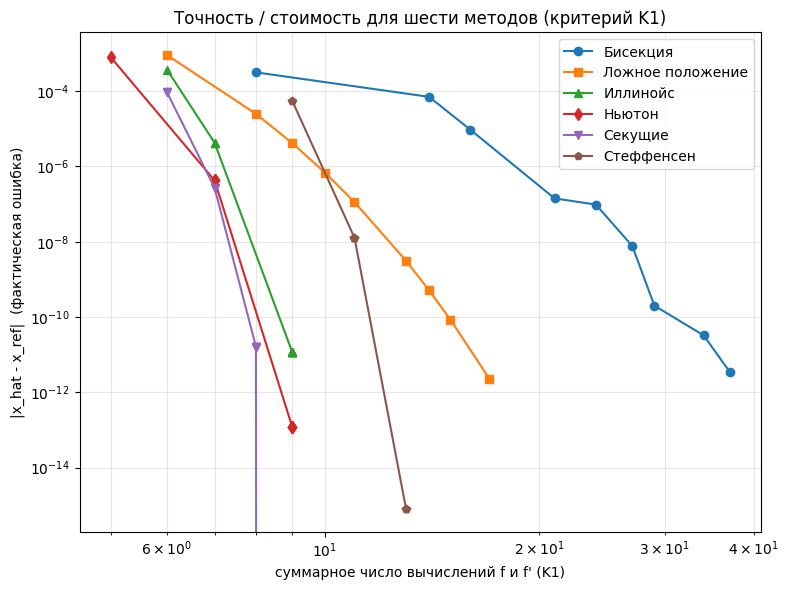

In [30]:
calls_bisection = [res[("Бисекция", "K1", e)]["calls"] for e in eps_list]
errors_bisection = [res[("Бисекция", "K1", e)]["err"] for e in eps_list]
calls_false = [res[("Ложное положение", "K1", e)]["calls"] for e in eps_list]
errors_false = [res[("Ложное положение", "K1", e)]["err"] for e in eps_list]
calls_illinois = [res[("Иллинойс", "K1", e)]["calls"] for e in eps_list]
errors_illinois = [res[("Иллинойс", "K1", e)]["err"] for e in eps_list]
calls_newton = [res[("Ньютон", "K1", e)]["calls"] for e in eps_list]
errors_newton = [res[("Ньютон", "K1", e)]["err"] for e in eps_list]
calls_secant = [res[("Секущие", "K1", e)]["calls"] for e in eps_list]
errors_secant = [res[("Секущие", "K1", e)]["err"] for e in eps_list]
calls_steffensen = [res[("Стеффенсен", "K1", e)]["calls"] for e in eps_list]
errors_steffensen = [res[("Стеффенсен", "K1", e)]["err"] for e in eps_list]
fig, ax = plt.subplots(figsize=(8, 6))
ax.loglog(calls_bisection, errors_bisection, 'o-', label='Бисекция')
ax.loglog(calls_false, errors_false, 's-', label='Ложное положение')
ax.loglog(calls_illinois, errors_illinois, '^-', label='Иллинойс')
ax.loglog(calls_newton, errors_newton, 'd-', label='Ньютон')
ax.loglog(calls_secant, errors_secant, 'v-', label='Секущие')
ax.loglog(calls_steffensen, errors_steffensen, 'p-', label='Стеффенсен')
ax.set_xlabel("суммарное число вычислений f и f' (K1)")
ax.set_ylabel('|x_hat - x_ref|  (фактическая ошибка)')
ax.set_title('Точность / стоимость для шести методов (критерий K1)')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Методы, чьи кривые находятся ближе к левому нижнему углу графика, эффективнее: они дают меньшую ошибку при меньшем числе вычислений.

Прогон A: x0 = 0.5  (сходимость к положительному корню)
 n |        x_n |     f(x_n) |     x_n+f |   f(x_n+f) |          D | знак D |     k=D/f | знак k |      x_n+1
 0 |   0.500000 |   1.351279 |    1.8513 |   -16.0769 |   -17.4282 |      - |  -12.8975 |      - |   0.604770
 1 |   0.604770 |   0.706180 |    1.3110 |    -6.5841 |    -7.2902 |      - |  -10.3235 |      - |   0.673175
 2 |   0.673175 |   0.226886 |    0.9001 |    -1.7002 |    -1.9271 |      - |   -8.4936 |      - |   0.699888
 3 |   0.699888 |   0.027100 |    0.7270 |    -0.1829 |    -0.2100 |      - |   -7.7486 |      - |   0.703385
 4 |   0.703385 |   0.000414 |    0.7038 |    -0.0028 |    -0.0032 |      - |   -7.6497 |      - |   0.703440
 5 |   0.703440 |   0.000000 |    0.7034 |    -0.0000 |    -0.0000 |      - |   -7.6482 |      - |   0.703440
знаки k по итерациям: - - - - - -



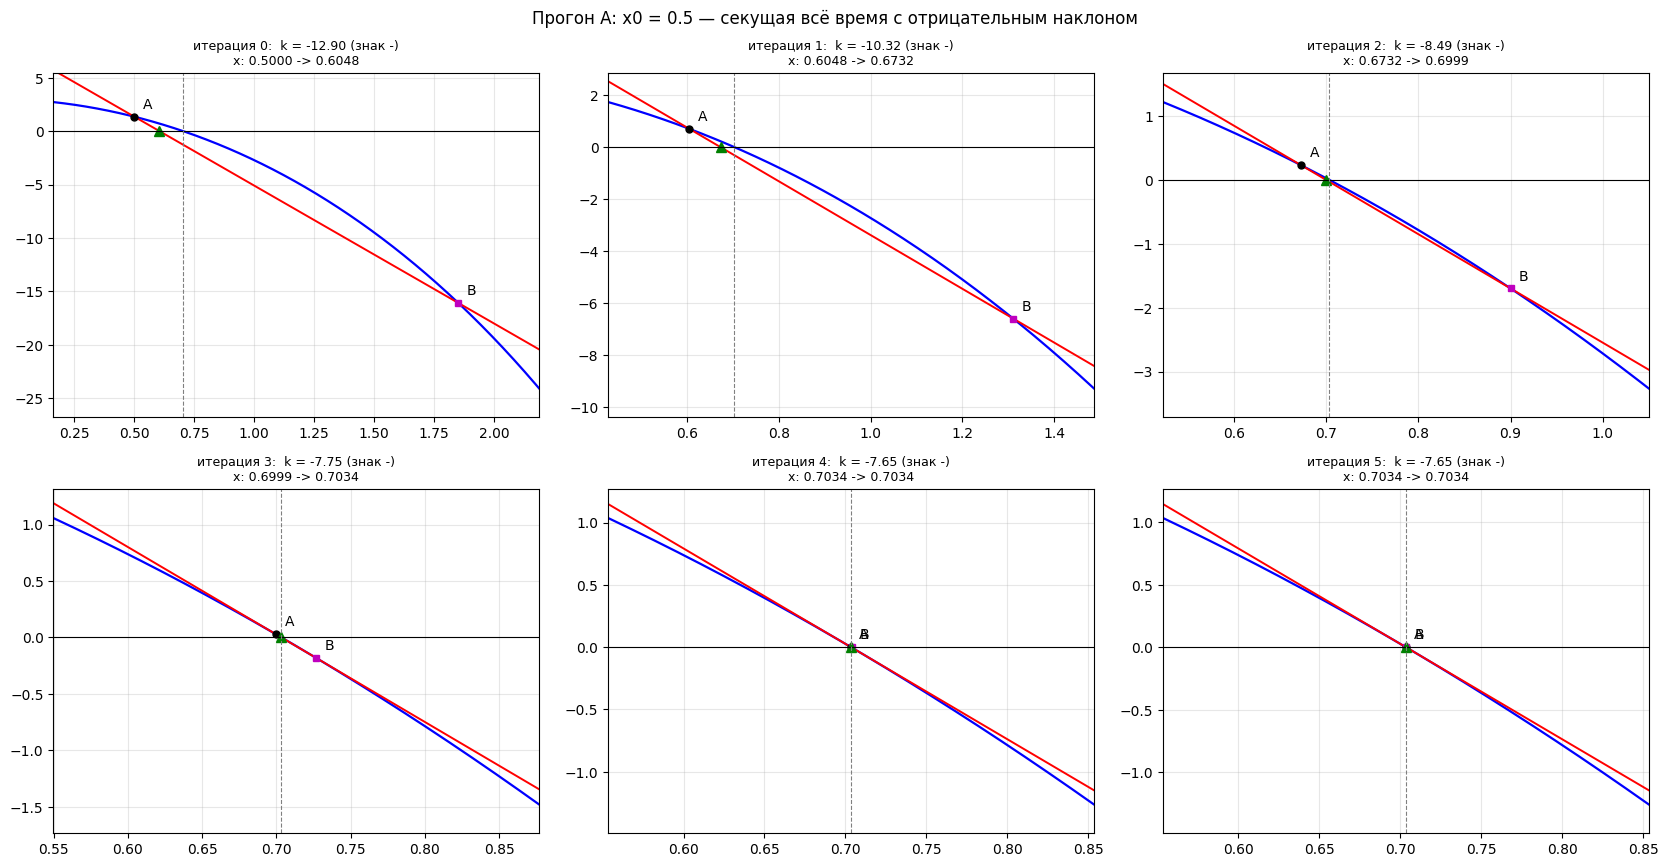

Прогон B: x0 = 0.92  (уход в отрицательноое)
 n |        x_n |     f(x_n) |     x_n+f |   f(x_n+f) |          D | знак D |     k=D/f | знак k |      x_n+1
 0 |   0.920000 |  -1.894890 |   -0.9749 |    -0.1789 |     1.7160 |      + |   -0.9056 |      - |  -1.172416
 1 |  -1.172416 |  -1.807852 |   -2.9803 |   -31.5788 |   -29.7709 |      - |   16.4676 |      + |  -1.062633
 2 |  -1.062633 |  -0.862301 |   -1.9249 |   -10.9674 |   -10.1051 |      - |   11.7187 |      + |  -0.989050
 3 |  -0.989050 |  -0.284809 |   -1.2739 |    -2.7706 |    -2.4858 |      - |    8.7280 |      + |  -0.956418
 4 |  -0.956418 |  -0.043210 |   -0.9996 |    -0.3650 |    -0.3218 |      - |    7.4481 |      + |  -0.950617
 5 |  -0.950617 |  -0.001191 |   -0.9518 |    -0.0098 |    -0.0086 |      - |    7.2234 |      + |  -0.950452
знаки k по итерациям: - + + + + +



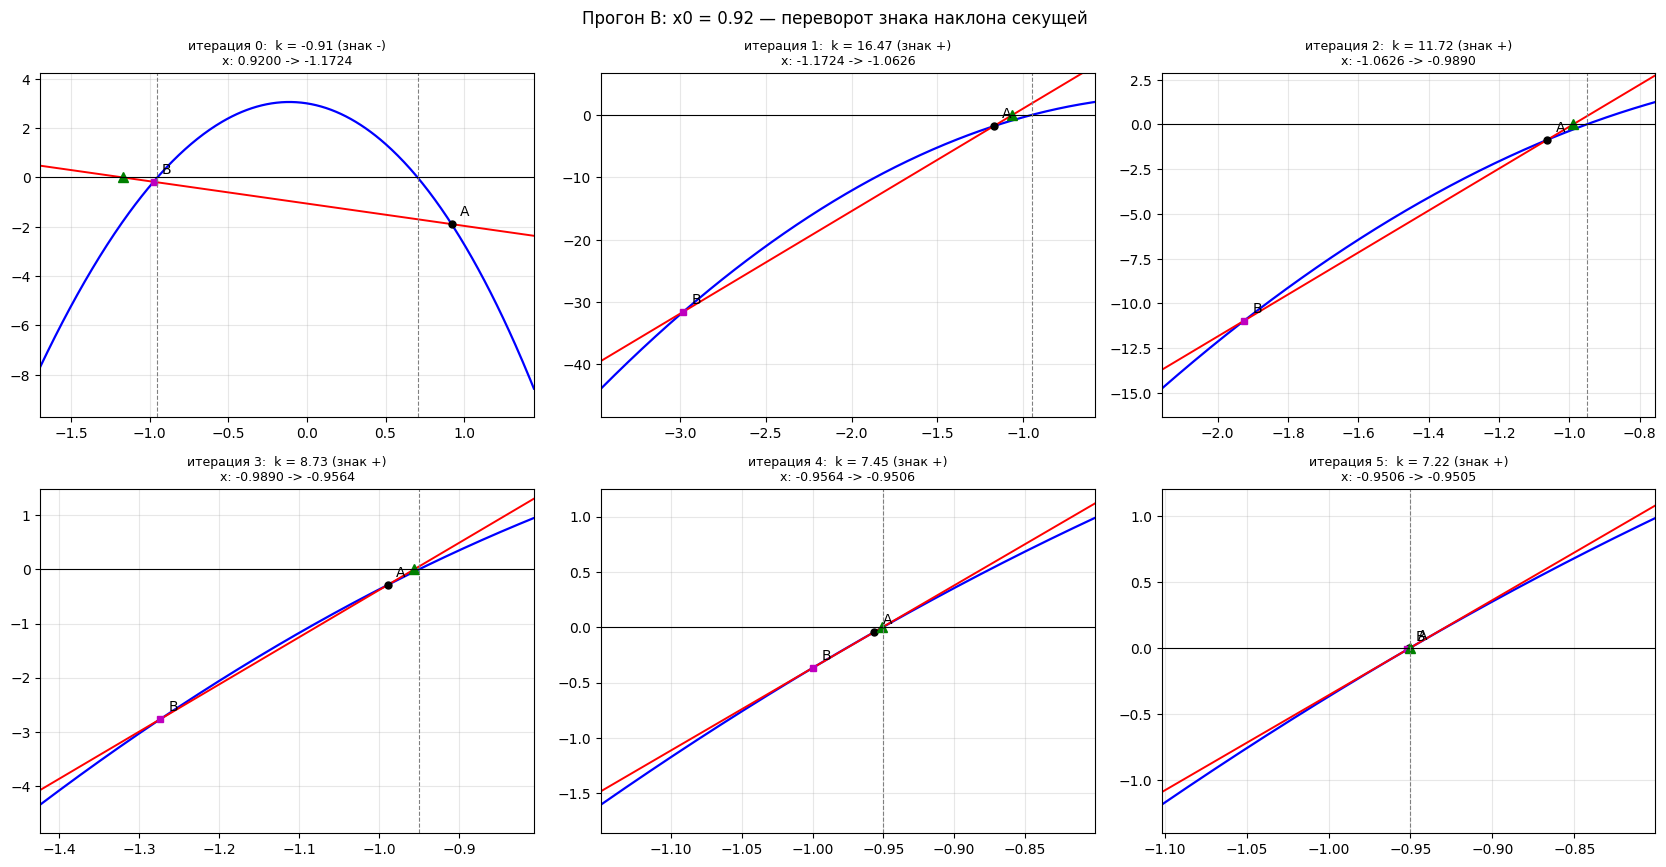

In [31]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 4.0 * (1.0 - x * x) - np.exp(x)

# опорные корни для пунктирных линий
def bis(a, b, iters=80):
    fa = f(a)
    for _ in range(iters):
        c = 0.5 * (a + b)
        fc = f(c)
        if fa * fc < 0: b = c
        else: a, fa = c, fc
    return 0.5 * (a + b)

X_POS = bis(0.0, 1.0)      # ≈ 0.70344
X_NEG = bis(-2.0, -0.5)    # ≈ -0.95045

def trace(x0, max_iter=6, eps=1e-12):
    """Одна строка на итерацию: все величины секущей Стеффенсена."""
    rows = []
    x, fx = float(x0), f(float(x0))
    for n in range(max_iter):
        xa, fa = x + fx, f(x + fx)          # вспомогательная точка B
        D = fa - fx                          # знаменатель = Δy на прыжке
        if abs(D) < 1e-14:
            rows.append(dict(n=n, x=x, fx=fx, xa=xa, fa=fa, D=D, k=np.nan, xn=x))
            break
        k = D / fx                           # наклон секущей
        xn = x - fx * fx / D                 # пересечение секущей с осью
        rows.append(dict(n=n, x=x, fx=fx, xa=xa, fa=fa, D=D, k=k, xn=xn))
        if abs(xn - x) <= eps:
            break
        x, fx = xn, f(xn)
    return rows

def show(rows, title):
    print('=' * 118); print(title); print('=' * 118)
    print(f"{'n':>2} | {'x_n':>10} | {'f(x_n)':>10} | {'x_n+f':>9} | {'f(x_n+f)':>10} | "
          f"{'D':>10} | {'знак D':>6} | {'k=D/f':>9} | {'знак k':>6} | {'x_n+1':>10}")
    for r in rows:
        sd = '+' if r['D'] > 0 else '-'
        sk = '+' if r['k'] > 0 else '-'
        print(f"{r['n']:>2} | {r['x']:>10.6f} | {r['fx']:>10.6f} | {r['xa']:>9.4f} | {r['fa']:>10.4f} | "
              f"{r['D']:>10.4f} | {sd:>6} | {r['k']:>9.4f} | {sk:>6} | {r['xn']:>10.6f}")
    print('знаки k по итерациям: ' + ' '.join('+' if r['k'] > 0 else '-' for r in rows))
    print()

def plot_run(rows, title, ncols=3):
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 4.4 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for r, ax in zip(rows, axes.ravel()):
        ax.axis('on')
        pts = [r['x'], r['xa'], r['xn']]
        lo, hi = min(pts), max(pts)
        pad = max(0.25 * (hi - lo), 0.15)
        lo, hi = lo - pad, hi + pad
        t = np.linspace(lo, hi, 400)
        ax.plot(t, f(t), 'b-', lw=1.6, label='f(x)')
        if np.isfinite(r['k']):
            ax.plot(t, r['fx'] + r['k'] * (t - r['x']), 'r-', lw=1.4,
                    label=f"секущая k={r['k']:.2f}")
        ax.plot([r['x']], [r['fx']], 'ko', ms=5); ax.annotate('A', (r['x'], r['fx']),
                                                              textcoords='offset points', xytext=(6, 6))
        ax.plot([r['xa']], [r['fa']], 'ms', ms=5); ax.annotate('B', (r['xa'], r['fa']),
                                                               textcoords='offset points', xytext=(6, 6))
        ax.plot([r['xn']], [0], 'g^', ms=7)
        ax.axhline(0, color='k', lw=0.8)
        for xr in (X_POS, X_NEG):
            if lo < xr < hi:
                ax.axvline(xr, color='0.5', ls='--', lw=0.8)
        yc = f(t)
        ylo, yhi = min(yc.min(), 0), max(yc.max(), 0)
        yp = 0.1 * (yhi - ylo) + 1e-9
        ax.set_xlim(lo, hi); ax.set_ylim(ylo - yp, yhi + yp)
        sk = '+' if r['k'] > 0 else '-'
        ax.set_title(f"итерация {r['n']}:  k = {r['k']:.2f} (знак {sk})\n"
                     f"x: {r['x']:.4f} -> {r['xn']:.4f}", fontsize=9)
        ax.grid(alpha=0.3)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()

# --- прогон A: старт слева от корня, знак наклона не меняется ---
rows_a = trace(0.5)
show(rows_a, 'Прогон A: x0 = 0.5  (сходимость к положительному корню)')
plot_run(rows_a, 'Прогон A: x0 = 0.5 — секущая всё время с отрицательным наклоном')

# --- прогон B: старт справа, первый шаг перебрасывает на левую ветвь — знак переворачивается ---
rows_b = trace(0.92)
show(rows_b, 'Прогон B: x0 = 0.92  (уход в отрицательноое)')
plot_run(rows_b, 'Прогон B: x0 = 0.92 — переворот знака наклона секущей')